# Response Post: Two-Dimensional Versions of a Classmate's Three-Dimensional Scatter Plot

This notebook rebuilds a classmate's three-dimensional scatter plot of the Auto MPG data set as three separate two-dimensional scatter plots, one for each pair of variables:

1. Horsepower and weight
2. Horsepower and fuel economy (miles per gallon)
3. Weight and fuel economy (miles per gallon)

Every chart keeps the original color gradient (`viridis`, mapped to miles per gallon), so all three variables are still visible in each chart. Numbered gold stars mark the minimum and maximum of each variable.

Data: Auto MPG Dataset, Kaggle, https://www.kaggle.com/datasets/uciml/autompg-dataset (file `auto-mpg.csv`, attached by a classmate).

In [1]:
# Import the libraries
import io
import pandas as pd
import matplotlib.pyplot as plt

# Two-dimensional charts do not need rotation, so the standard inline backend is used
%matplotlib inline

In [2]:
# Load the data set.
# The attached auto-mpg.csv wraps every row in quotation marks, which makes pandas read the
# whole row as one column. Removing the outer quotation marks first fixes this, and the code
# still works if the file is a normal comma-separated file.
with open('auto-mpg.csv', encoding='utf-8-sig') as file:
    rows = [line.strip() for line in file if line.strip()]
rows = [row[1:-1] if row.startswith('"') and row.endswith('"') else row for row in rows]
df = pd.read_csv(io.StringIO('\n'.join(rows)), skipinitialspace=True)

# Convert the three plotted columns to numbers and drop rows with missing values
# (six cars list horsepower as "?")
for column in ['horsepower', 'weight', 'mpg']:
    df[column] = pd.to_numeric(df[column], errors='coerce')
rows_before = len(df)
df = df.dropna(subset=['horsepower', 'weight', 'mpg']).reset_index(drop=True)
print(f'Rows in file: {rows_before}   Rows plotted: {len(df)}   Rows dropped: {rows_before - len(df)}')

# Readable car names for the chart key (the file stores them in lowercase with short forms)
name_fixes = {'hi 1200d': 'International Harvester 1200D',
              'pontiac safari (sw)': 'Pontiac Safari Station Wagon'}
df['display_name'] = df['car name'].map(name_fixes).fillna(df['car name'].str.title())
df['display_name'] = df['display_name'].str.replace('Glc', 'GLC')
df['year'] = 1900 + df['model year']
df[['display_name', 'year', 'horsepower', 'weight', 'mpg']].describe()

Rows in file: 398   Rows plotted: 392   Rows dropped: 6


,year,horsepower,weight,mpg
count,392.000000,392.000000,392.000000,392.000000
mean,1975.979592,104.469388,2977.584184,23.445918
std,3.683737,38.491160,849.402560,7.805007
min,1970.000000,46.000000,1613.000000,9.000000
25%,1973.000000,75.000000,2225.250000,17.000000
50%,1976.000000,93.500000,2803.500000,22.750000
75%,1979.000000,126.000000,3614.750000,29.000000
max,1982.000000,230.000000,5140.000000,46.600000


In [3]:
# Find the minimum and maximum of each variable (ties are kept)
extremes = [
    (1, 'Lowest fuel economy', 'mpg', 'min'),
    (2, 'Highest fuel economy', 'mpg', 'max'),
    (3, 'Lowest horsepower', 'horsepower', 'min'),
    (4, 'Highest horsepower', 'horsepower', 'max'),
    (5, 'Lightest weight', 'weight', 'min'),
    (6, 'Heaviest weight', 'weight', 'max'),
]
extreme_rows = []
for number, label, column, kind in extremes:
    target = df[column].min() if kind == 'min' else df[column].max()
    matches = df[df[column] == target]
    for _, row in matches.iterrows():
        extreme_rows.append({'number': number, 'label': label, 'car': row['display_name'],
                             'year': row['year'], 'horsepower': row['horsepower'],
                             'weight': row['weight'], 'mpg': row['mpg']})
extreme_table = pd.DataFrame(extreme_rows)
extreme_table

,number,label,car,year,horsepower,weight,mpg
0,1,Lowest fuel economy,International Harvester 1200D,1970,193.0,4732,9.0
1,2,Highest fuel economy,Mazda GLC,1980,65.0,2110,46.6
2,3,Lowest horsepower,Volkswagen 1131 Deluxe Sedan,1970,46.0,1835,26.0
3,3,Lowest horsepower,Volkswagen Super Beetle,1973,46.0,1950,26.0
4,4,Highest horsepower,Pontiac Grand Prix,1973,230.0,4278,16.0
5,5,Lightest weight,Datsun 1200,1971,69.0,1613,35.0
6,6,Heaviest weight,Pontiac Safari Station Wagon,1971,175.0,5140,13.0


In [4]:
# Labels written out in full
axis_labels = {'horsepower': 'Horsepower',
               'weight': 'Weight (pounds)',
               'mpg': 'Fuel Economy (miles per gallon)'}

# Build the text for the key box once, so every chart uses the same key
key_lines = []
for number, group in extreme_table.groupby('number', sort=True):
    first = group.iloc[0]
    key_lines.append(f"{number}. {first['label']}: " + ', '.join(f"{r.car} ({r.year})" for r in group.itertuples()))
    for r in group.itertuples():
        key_lines.append(f"      {r.horsepower:.0f} horsepower, {r.weight:,.0f} pounds, {r.mpg:.1f} miles per gallon")
key_text = 'Gold stars (minimum and maximum of each variable)\n\n' + '\n'.join(key_lines)

# Small offsets (in points) for the star numbers so they do not cover each other
label_offsets = {1: (10, 6), 2: (10, 6), 3: (-16, 8), 4: (10, 6), 5: (-16, -14), 6: (10, -14)}


def draw_2d_scatter(x_column, y_column, title, file_name, legend_location='upper right'):
    """Draw one two-dimensional scatter plot, mark the extremes, and save it as a PNG."""
    fig, ax = plt.subplots(figsize=(11, 10.5))
    fig.subplots_adjust(left=0.09, right=0.98, top=0.92, bottom=0.38)

    # Customization 1 and 2: viridis color gradient mapped to fuel economy, circle markers with white edges
    points = ax.scatter(df[x_column], df[y_column], c=df['mpg'], cmap='viridis',
                        marker='o', s=60, alpha=0.8, edgecolors='white', linewidths=0.6)

    # Colorbar label matches the fuel economy axis label
    colorbar = fig.colorbar(points, ax=ax, pad=0.02)
    colorbar.set_label(axis_labels['mpg'], fontsize=12, labelpad=10)

    # Numbered gold stars on the minimum and maximum of each variable
    ax.scatter(extreme_table[x_column], extreme_table[y_column], marker='*', s=420,
               color='gold', edgecolors='black', linewidths=1.0, zorder=5,
               label='Minimum or maximum of a variable')
    for r in extreme_table.itertuples():
        ax.annotate(str(r.number), (getattr(r, x_column), getattr(r, y_column)),
                    xytext=label_offsets[r.number], textcoords='offset points',
                    fontsize=12, fontweight='bold', zorder=6)

    # Customization 3: axis label padding, a light grid, and a title
    ax.set_xlabel(axis_labels[x_column], fontsize=13, labelpad=12)
    ax.set_ylabel(axis_labels[y_column], fontsize=13, labelpad=12)
    ax.set_title(title, fontsize=15, fontweight='bold', pad=14)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.margins(0.06)
    ax.legend(loc=legend_location, fontsize=10, framealpha=0.95)

    # Key box and source line below the chart
    fig.text(0.09, 0.025, key_text, fontsize=10.5, va='bottom', ha='left', family='monospace',
             bbox=dict(boxstyle='round,pad=0.6', facecolor='lightyellow', edgecolor='gray'))
    fig.text(0.98, 0.005, 'Source: Auto MPG Dataset, Kaggle (392 cars, model years 1970 to 1982)',
             fontsize=9, color='dimgray', ha='right', va='bottom')

    fig.savefig(file_name, dpi=150)
    plt.show()
    return fig

## Chart 1: Horsepower and Weight

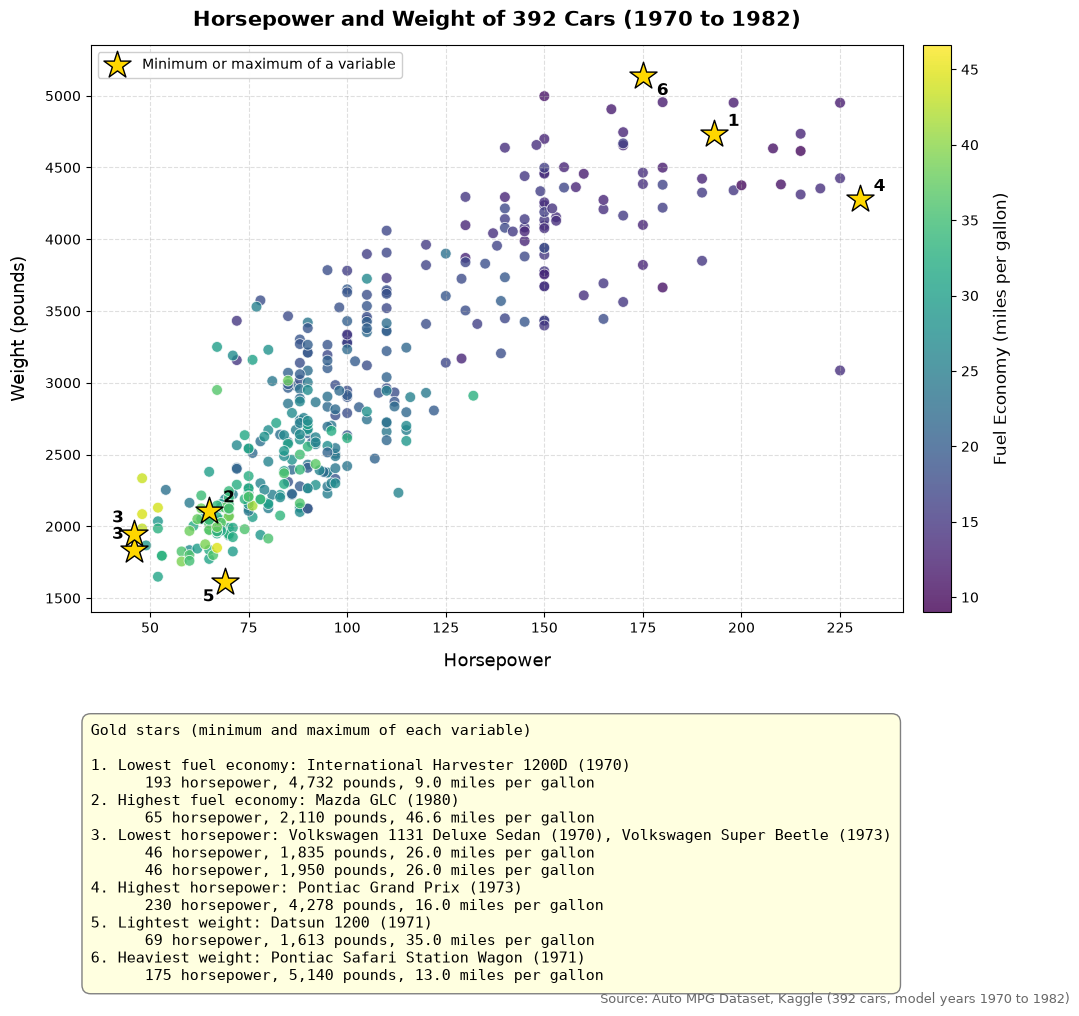

In [5]:
fig1 = draw_2d_scatter('horsepower', 'weight',
                       'Horsepower and Weight of 392 Cars (1970 to 1982)',
                       'chart1_horsepower_weight.png', legend_location='upper left')

## Chart 2: Horsepower and Fuel Economy

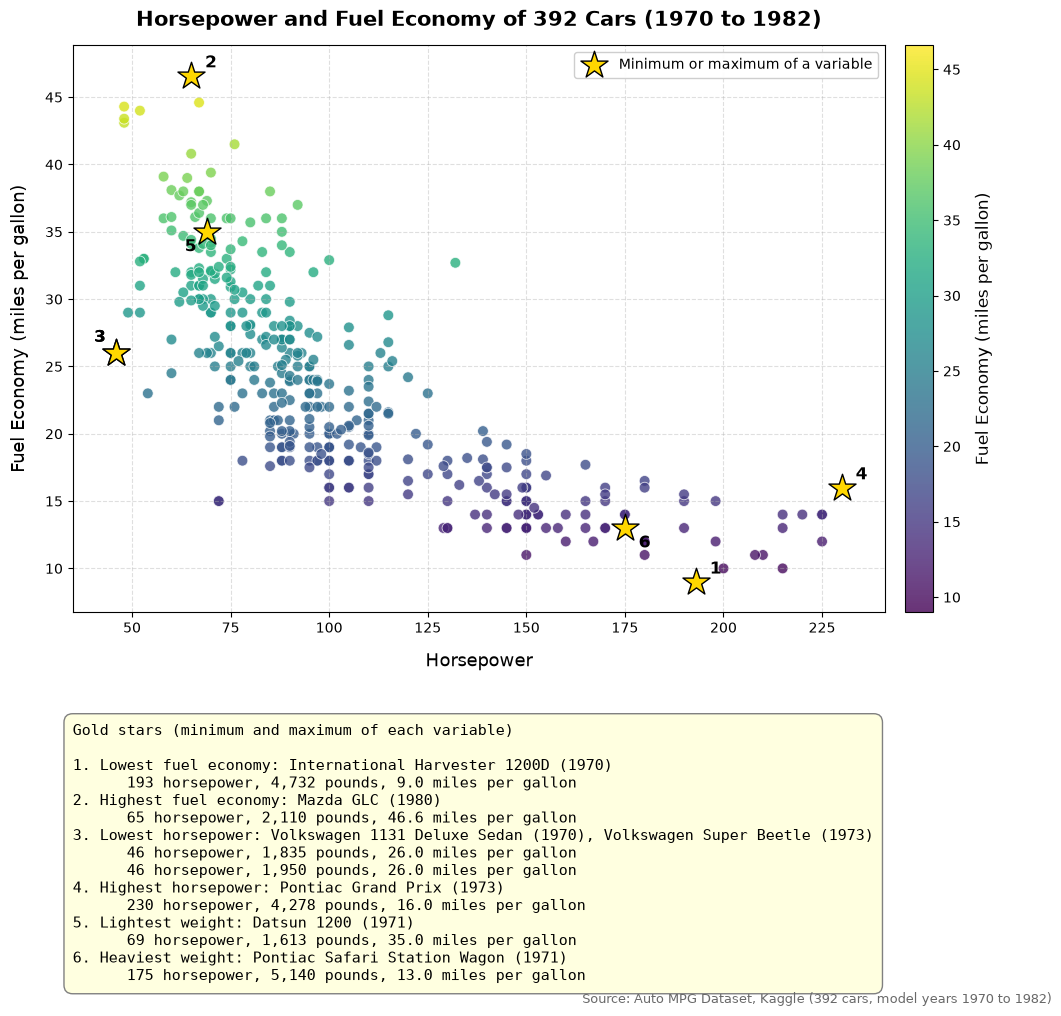

In [6]:
fig2 = draw_2d_scatter('horsepower', 'mpg',
                       'Horsepower and Fuel Economy of 392 Cars (1970 to 1982)',
                       'chart2_horsepower_mpg.png')

## Chart 3: Weight and Fuel Economy

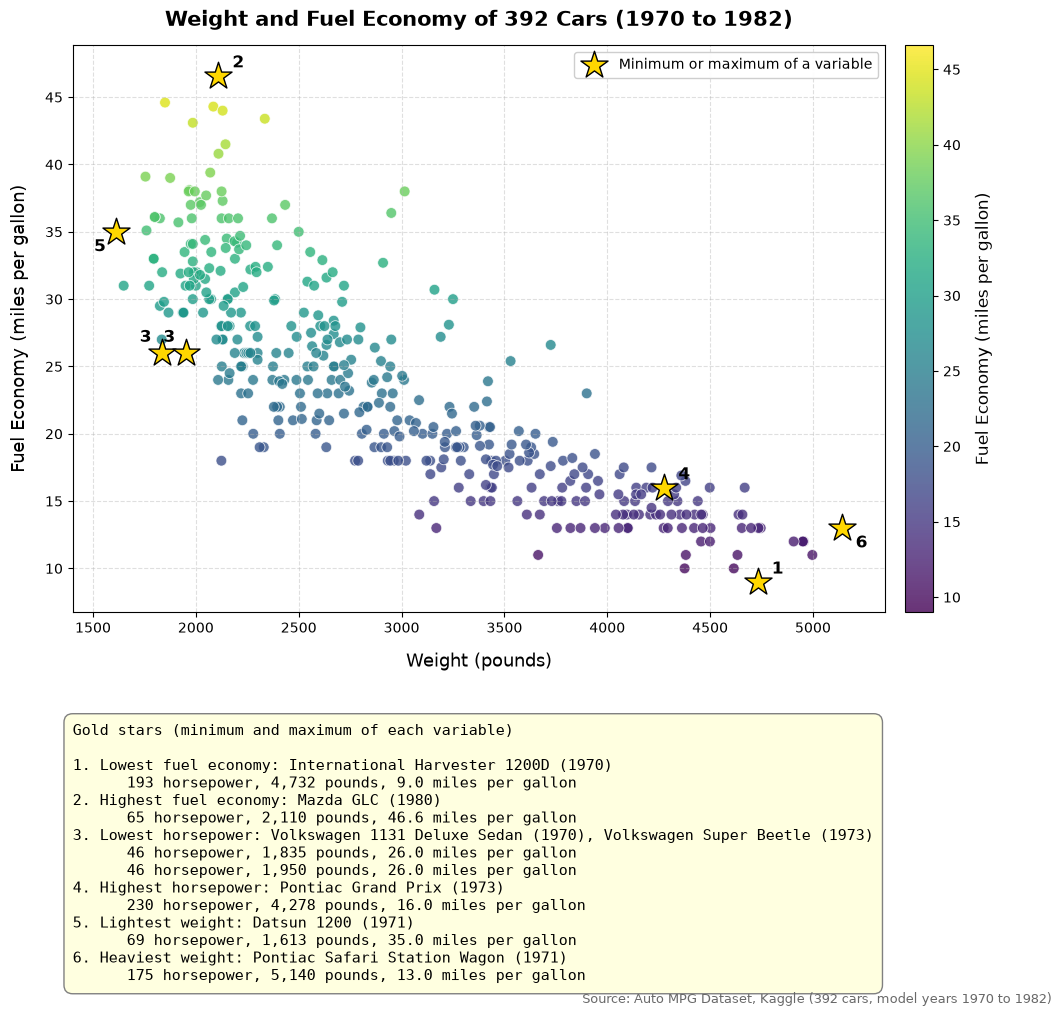

In [7]:
fig3 = draw_2d_scatter('weight', 'mpg',
                       'Weight and Fuel Economy of 392 Cars (1970 to 1982)',
                       'chart3_weight_mpg.png')

## Supporting Numbers

In [8]:
# Correlation between each pair of variables
print('Correlations')
print(df[['horsepower', 'weight', 'mpg']].corr().round(2))

# Heavy and powerful cars (over 4,000 pounds and over 150 horsepower)
heavy = df[(df['weight'] > 4000) & (df['horsepower'] > 150)]
print(f"\nCars over 4,000 pounds and 150 horsepower: {len(heavy)}")
print(f"  Highest fuel economy in this group: {heavy['mpg'].max():.1f} miles per gallon")
print(f"  Share at 15 miles per gallon or less: {(heavy['mpg'] <= 15).mean() * 100:.0f} percent")

# Light cars (under 2,500 pounds)
light = df[df['weight'] < 2500]
print(f"\nCars under 2,500 pounds: {len(light)}")
print(f"  Median fuel economy: {light['mpg'].median():.1f} miles per gallon")

# Cars between 2,500 and 3,000 pounds show how much fuel economy still varies at one weight
middle = df[(df['weight'] >= 2500) & (df['weight'] <= 3000)]
print(f"\nCars from 2,500 to 3,000 pounds: {len(middle)}")
print(f"  Fuel economy range: {middle['mpg'].min():.1f} to {middle['mpg'].max():.1f} miles per gallon")

# Median fuel economy by model year
print('\nMedian fuel economy by model year')
print(df.groupby('year')['mpg'].median().round(1).to_string())

Correlations
            horsepower  weight   mpg
horsepower        1.00    0.86 -0.78
weight            0.86    1.00 -0.83
mpg              -0.78   -0.83  1.00

Cars over 4,000 pounds and 150 horsepower: 37
  Highest fuel economy in this group: 16.9 miles per gallon
  Share at 15 miles per gallon or less: 81 percent

Cars under 2,500 pounds: 143
  Median fuel economy: 30.0 miles per gallon

Cars from 2,500 to 3,000 pounds: 82
  Fuel economy range: 18.0 to 36.4 miles per gallon

Median fuel economy by model year
year
1970    16.0
1971    19.0
1972    18.5
1973    16.0
1974    24.5
1975    19.5
1976    21.0
1977    21.8
1978    20.7
1979    23.9
1980    32.7
1981    31.2
1982    32.0
